# Demand Regression

## 1. Load Processed Dataset

### Objective
Load the feature-engineered dataset created in the previous stage.

### Reasoning
All modelling should use the same validated and leakage-safe feature set.
The processed dataset contains 29 candidate predictors and the next-week
demand target.

In [33]:
import sklearn
import pandas
import numpy
import joblib

print("scikit-learn:", sklearn.__version__)
print("pandas:", pandas.__version__)
print("NumPy:", numpy.__version__)
print("joblib:", joblib.__version__)

scikit-learn: 1.9.0
pandas: 3.0.3
NumPy: 2.5.1
joblib: 1.5.3


In [1]:
import pandas as pd
import numpy as np

file_path = "../data/processed/smartmarkdown_feature_engineered.csv"

df = pd.read_csv(
    file_path,
    parse_dates=["Week_Start"]
)

print("Shape:", df.shape)
print("Date Range:", df["Week_Start"].min(), "to", df["Week_Start"].max())
print("Unique SKUs:", df["SKU_ID"].nunique())

Shape: (3840, 35)
Date Range: 2024-02-26 00:00:00 to 2025-12-22 00:00:00
Unique SKUs: 40


In [2]:
new_features = [
    "Units_Sold",
    "Views",
    "Cart_Adds",
    "Stockout_Flag"
]

print(df[new_features].head())
print(df[new_features].isnull().sum())

   Units_Sold  Views  Cart_Adds  Stockout_Flag
0          52   1165        139              0
1          69   1258        181              0
2          67   1070        155              0
3          79   1560        200              0
4         119   1811        151              0
Units_Sold       0
Views            0
Cart_Adds        0
Stockout_Flag    0
dtype: int64


## 2. Define Predictors and Target

### Objective
Separate the predictor variables from the next-week demand target.

### Target
Future_Latent_Demand

The model will learn from information available at Week t to predict
Latent_Demand for Week t+1.

In [3]:
# ---------------------------------------------------------
# Forecast Target Week
# ---------------------------------------------------------

df["Target_Week"] = (df["Week_Start"] + pd.Timedelta(days=7)
)

df[["Week_Start", "Target_Week", "Future_Latent_Demand"]].head()

,Week_Start,Target_Week,Future_Latent_Demand
0,2024-02-26,2024-03-04,69.0
1,2024-03-04,2024-03-11,67.0
2,2024-03-11,2024-03-18,79.0
3,2024-03-18,2024-03-25,119.0
4,2024-03-25,2024-04-01,69.0


In [4]:
target_col = "Future_Latent_Demand"

feature_cols = [
    col for col in df.columns
    if col not in ["Week_Start", "Target_Week", target_col]
]

X = df[feature_cols].copy()
y = df[target_col].copy()

print("Number of Features:", len(feature_cols))
print("X Shape:", X.shape)
print("y Shape:", y.shape)

Number of Features: 33
X Shape: (3840, 33)
y Shape: (3840,)


## 3. Chronological Train / Validation / Test Split

### Objective
Split the dataset by time so that training observations occur before
validation and test observations.

### Reasoning
Random splitting is not appropriate for time-dependent forecasting because it
can allow future information to influence model development.

The model should be trained on earlier periods and evaluated on later,
unseen periods to simulate real-world forecasting.

In [5]:
# ---------------------------------------------------------
# Chronological Split Using Unique Weeks
# ---------------------------------------------------------

unique_weeks = (
    df["Week_Start"]
    .drop_duplicates()
    .sort_values()
    .reset_index(drop=True)
)

n_weeks = len(unique_weeks)

train_end = int(n_weeks * 0.70)
val_end = int(n_weeks * 0.85)

train_weeks = unique_weeks.iloc[:train_end]
val_weeks = unique_weeks.iloc[train_end:val_end]
test_weeks = unique_weeks.iloc[val_end:]

print("Total Weeks:", n_weeks)

print("Train Weeks:", len(train_weeks))
print("Validation Weeks:", len(val_weeks))
print("Test Weeks:", len(test_weeks))

Total Weeks: 96
Train Weeks: 67
Validation Weeks: 14
Test Weeks: 15


In [6]:
train_df = df[df["Week_Start"].isin(train_weeks)].copy()

val_df = df[df["Week_Start"].isin(val_weeks)].copy()

test_df = df[df["Week_Start"].isin(test_weeks)].copy()

### Split Strategy

A 70% / 15% / 15% chronological split is used for training, validation
and testing.

The 70% training portion provides sufficient historical data for model learning,
while the validation and test portions each retain several weeks of unseen future
observations for reliable model comparison and final evaluation.

The exact percentages are a practical choice rather than a strict rule.
Maintaining chronological order is more important than the specific ratio.

## 4. Verify Split

In [7]:
def split_summary(name, data):
    print(
        f"{name}: {data.shape}",
        "| Feature Weeks:",
        data["Week_Start"].min(),
        "to",
        data["Week_Start"].max(),
        "| Target Weeks:",
        data["Target_Week"].min(),
        "to",
        data["Target_Week"].max()
    )

split_summary("Train", train_df)
split_summary("Validation", val_df)
split_summary("Test", test_df)

Train: (2680, 36) | Feature Weeks: 2024-02-26 00:00:00 to 2025-06-02 00:00:00 | Target Weeks: 2024-03-04 00:00:00 to 2025-06-09 00:00:00
Validation: (560, 36) | Feature Weeks: 2025-06-09 00:00:00 to 2025-09-08 00:00:00 | Target Weeks: 2025-06-16 00:00:00 to 2025-09-15 00:00:00
Test: (600, 36) | Feature Weeks: 2025-09-15 00:00:00 to 2025-12-22 00:00:00 | Target Weeks: 2025-09-22 00:00:00 to 2025-12-29 00:00:00


In [8]:
print("\nTrain/Test Overlap:",len(set(train_df["Week_Start"])& set(test_df["Week_Start"])))

print("Validation/Test Overlap:",len(set(val_df["Week_Start"])& set(test_df["Week_Start"])))


Train/Test Overlap: 0
Validation/Test Overlap: 0


## 5. Check SKU coverage in every split

In [9]:
print("Train SKUs:", train_df["SKU_ID"].nunique())
print("Validation SKUs:", val_df["SKU_ID"].nunique())
print("Test SKUs:", test_df["SKU_ID"].nunique())

Train SKUs: 40
Validation SKUs: 40
Test SKUs: 40


## 6. Target distribution by split

In [10]:
split_target_summary = pd.DataFrame({
    "Train": train_df[target_col].describe(),
    "Validation": val_df[target_col].describe(),
    "Test": test_df[target_col].describe()
})

display(split_target_summary)

,Train,Validation,Test
count,2680.000000,560.000000,600.000000
mean,37.819776,37.275000,41.031667
std,16.793366,15.613263,19.045171
min,6.000000,7.000000,7.000000
25%,26.000000,26.000000,28.000000
50%,35.000000,34.000000,37.500000
75%,46.000000,47.000000,49.250000
max,134.000000,96.000000,143.000000


In [11]:
print(
    "Train Mean Demand:",
    round(train_df[target_col].mean(), 2)
)

print(
    "Validation Mean Demand:",
    round(val_df[target_col].mean(), 2)
)

print(
    "Test Mean Demand:",
    round(test_df[target_col].mean(), 2)
)

Train Mean Demand: 37.82
Validation Mean Demand: 37.28
Test Mean Demand: 41.03


## Baseline

In [12]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

def evaluate_regression(y_true, y_pred):

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    wape = (np.abs(y_true - y_pred).sum() / np.abs(y_true).sum() * 100)
    r2 = r2_score(y_true, y_pred)

    return pd.Series({
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "WAPE (%)": round(wape, 2),
        "R2": round(r2, 3)
    })

In [13]:
y_val = val_df["Future_Latent_Demand"]

baseline_val_pred = val_df["Rolling_4W_Avg_Demand"]

baseline_metrics = evaluate_regression(y_val,baseline_val_pred)

display(baseline_metrics.to_frame(name="4W Average Baseline"))

,4W Average Baseline
MAE,7.120
RMSE,9.440
WAPE (%),19.090
R2,0.634


## 7. Identify Numerical and Categorical Features

#### Objective
Separate categorical and numerical predictors before preprocessing.

#### Reasoning
Categorical variables require encoding, while numerical variables may require
scaling depending on the regression model.

All preprocessing transformations will be fitted only on the training data
to avoid information leakage.

In [14]:
# ---------------------------------------------------------
# Separate Categorical and Numerical Features
# ---------------------------------------------------------

categorical_features = [
    "SKU_ID",
    "Category",
    "Subcategory",
    "Brand",
    "Future_Retail_Event",
    "Future_Season_Tag"
]

numerical_features = [
    col for col in feature_cols
    if col not in categorical_features
]

print("Categorical Features:", len(categorical_features))
print(categorical_features)

print("\nNumerical Features:", len(numerical_features))
print(numerical_features)

print("\nTotal Features:",
      len(categorical_features) + len(numerical_features))

Categorical Features: 6
['SKU_ID', 'Category', 'Subcategory', 'Brand', 'Future_Retail_Event', 'Future_Season_Tag']

Numerical Features: 27
['Future_Month', 'Future_Quarter', 'Future_Week_of_Year', 'Future_Festival_Flag', 'Lag_1_Demand', 'Lag_2_Demand', 'Lag_4_Demand', 'Rolling_4W_Avg_Demand', 'Rolling_8W_Avg_Demand', 'Rolling_4W_Std_Demand', 'Discount_Pct', 'Price_Index', 'Competitor_Gap_Pct', 'Unit_Margin', 'Closing_Inventory', 'Days_In_Inventory', 'Sell_Through', 'Weeks_of_Supply', 'Inventory_Pressure', 'Lag_1_Views', 'Lag_1_Cart_Adds', 'Rolling_4W_Avg_Views', 'Rolling_4W_Avg_Cart_Adds', 'Units_Sold', 'Views', 'Cart_Adds', 'Stockout_Flag']

Total Features: 33


## 8. Verify Data Types 

In [15]:
print("\nCategorical Data Types:")
display(df[categorical_features].dtypes)

print("\nNumerical Data Types:")
display(df[numerical_features].dtypes)


Categorical Data Types:


SKU_ID                 str
Category               str
Subcategory            str
Brand                  str
Future_Retail_Event    str
Future_Season_Tag      str
dtype: object


Numerical Data Types:


Future_Month                float64
Future_Quarter              float64
Future_Week_of_Year         float64
Future_Festival_Flag        float64
Lag_1_Demand                float64
Lag_2_Demand                float64
Lag_4_Demand                float64
Rolling_4W_Avg_Demand       float64
Rolling_8W_Avg_Demand       float64
Rolling_4W_Std_Demand       float64
Discount_Pct                  int64
Price_Index                 float64
Competitor_Gap_Pct          float64
Unit_Margin                 float64
Closing_Inventory             int64
Days_In_Inventory             int64
Sell_Through                float64
Weeks_of_Supply             float64
Inventory_Pressure          float64
Lag_1_Views                 float64
Lag_1_Cart_Adds             float64
Rolling_4W_Avg_Views        float64
Rolling_4W_Avg_Cart_Adds    float64
Units_Sold                    int64
Views                         int64
Cart_Adds                     int64
Stockout_Flag                 int64
dtype: object

## 9. Training X and y

In [16]:
X_train = train_df[feature_cols].copy()
y_train = train_df[target_col].copy()

X_val = val_df[feature_cols].copy()
y_val = val_df[target_col].copy()

X_test = test_df[feature_cols].copy()
y_test = test_df[target_col].copy()

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (2680, 33)
X_val: (560, 33)
X_test: (600, 33)


## 10. Preprocessing Strategy

In [17]:
# Tree preprocessor
# Categorical - encoded
# Numerical   - unchanged

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

tree_preprocessor = ColumnTransformer(
    transformers=[
        ("cat",OneHotEncoder(handle_unknown="ignore",sparse_output=False),categorical_features),
        ("num","passthrough",numerical_features)
    ]
)

In [18]:
# linear preprocessor
# Categorical - One-Hot Encode
# Numerical  - Standardize

from sklearn.preprocessing import StandardScaler

linear_preprocessor = ColumnTransformer(
    transformers=[
        ("cat",OneHotEncoder(handle_unknown="ignore",sparse_output=False),categorical_features),
        ("num",StandardScaler(),numerical_features)
    ]
)

### Preprocessing Applied to Model Features

The model uses two types of preprocessing based on feature type.

#### 1. One-Hot Encoding
One-Hot Encoding is applied to categorical features so that text-based categories
can be converted into numerical form for model training.

Categorical features:
- SKU_ID
- Category
- Subcategory
- Brand
- Future_Retail_Event
- Future_Season_Tag

For example, a feature such as `Future_Retail_Event` is converted into separate
binary columns such as Diwali, Holi, No_Event, etc.

#### 2. Standard Scaling
Standard Scaling is applied only to numerical features for linear models.

The scaler transforms numerical variables so that they are on a comparable scale,
with approximately mean = 0 and standard deviation = 1.

Examples of numerical features being scaled include:
- Discount_Pct
- Price_Index
- Competitor_Gap_Pct
- Units_Sold
- Lag_1_Demand
- Lag_2_Demand
- Lag_4_Demand
- Rolling_4W_Avg_Demand
- Rolling_8W_Avg_Demand
- Rolling_4W_Std_Demand
- Closing_Inventory
- Days_In_Inventory
- Sell_Through
- Weeks_of_Supply
- Inventory_Pressure
- Views
- Cart_Adds
- Lag_1_Views
- Lag_1_Cart_Adds
- Rolling_4W_Avg_Views
- Rolling_4W_Avg_Cart_Adds
- Stockout_Flag
- Future_Month
- Future_Quarter
- Future_Week_of_Year
- Future_Festival_Flag

### Model-Specific Preprocessing

For Linear Regression and Ridge Regression:
- Categorical features → One-Hot Encoding
- Numerical features → Standard Scaling

For tree-based models such as Random Forest and Gradient Boosting:
- Categorical features → One-Hot Encoding
- Numerical features → Passed without scaling

All preprocessing is fitted only on the training data through a pipeline to avoid
data leakage.

## 11. Linear Regression Model

### Objective
Train a simple regression model to predict next-week latent demand.

### Reasoning
Linear Regression provides an interpretable baseline and helps determine
whether the engineered features improve forecasting beyond the simple
4-week moving-average benchmark.

Categorical features are one-hot encoded and numerical features are
standardized within the modelling pipeline.

In [19]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

linear_model = Pipeline(
    steps=[
        ("preprocessor", linear_preprocessor),
        ("model", LinearRegression())
    ]
)

linear_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the

In [20]:
# ---------------------------------------------------------
# Train Linear Regression
# ---------------------------------------------------------

linear_model.fit(X_train,y_train)

print("Linear Regression training completed.")

Linear Regression training completed.


In [21]:
# ---------------------------------------------------------
# Validation Predictions
# ---------------------------------------------------------

linear_val_pred = linear_model.predict(X_val)

print("Validation Predictions:", len(linear_val_pred))

Validation Predictions: 560


In [22]:
linear_metrics = evaluate_regression(y_val,linear_val_pred)

display(linear_metrics.to_frame(name="Linear Regression"))

,Linear Regression
MAE,6.360
RMSE,8.370
WAPE (%),17.050
R2,0.712


In [23]:
model_comparison = pd.DataFrame({
    "4W Average Baseline": baseline_metrics,
    "Linear Regression": linear_metrics
}).T

display(model_comparison)

,MAE,RMSE,WAPE (%),R2
4W Average Baseline,7.12,9.44,19.09,0.634
Linear Regression,6.36,8.37,17.05,0.712


### Linear Regression Result

Linear Regression outperformed the 4-week moving-average baseline across all
validation metrics.

- MAE improved from 7.12 to 6.36 units.
- RMSE improved from 9.44 to 8.37.
- WAPE reduced from 19.09% to 17.05%.
- R² increased from 0.634 to 0.712.

This indicates that the engineered pricing, inventory, calendar, demand-history,
and customer-interest features provide additional predictive information beyond
recent average demand alone.

## 12. Ridge Regression

### Objective
Train a regularized linear regression model and compare it with the
standard Linear Regression model.

### Reasoning
Several engineered predictors are strongly correlated. Ridge Regression
applies L2 regularization, which reduces coefficient magnitude and helps
stabilize the model when multicollinearity is present.

The same preprocessing pipeline is used:
- Categorical features - One-Hot Encoding
- Numerical features - Standard Scaling

In [24]:
from sklearn.linear_model import Ridge

ridge_model = Pipeline(
    steps=[
        ("preprocessor", linear_preprocessor),
        ("model", Ridge(alpha=1.0))
    ]
)

ridge_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the

In [25]:
# ---------------------------------------------------------
# Train Ridge Regression
# ---------------------------------------------------------

ridge_model.fit(X_train,y_train)

print("Ridge Regression training completed.")

Ridge Regression training completed.


In [27]:
ridge_val_pred = ridge_model.predict(X_val)

print("Validation Predictions:", len(ridge_val_pred))

Validation Predictions: 560


In [28]:
ridge_metrics = evaluate_regression(y_val,ridge_val_pred)

display(ridge_metrics.to_frame(name="Ridge Regression"))

,Ridge Regression
MAE,6.350
RMSE,8.380
WAPE (%),17.030
R2,0.712


In [29]:
model_comparison = pd.DataFrame({
    "4W Average Baseline": baseline_metrics,
    "Linear Regression": linear_metrics,
    "Ridge Regression": ridge_metrics
}).T

display(model_comparison)

,MAE,RMSE,WAPE (%),R2
4W Average Baseline,7.12,9.44,19.09,0.634
Linear Regression,6.36,8.37,17.05,0.712
Ridge Regression,6.35,8.38,17.03,0.712


#### Ridge Regression Result before tuning alpha

Ridge Regression produced performance very similar to standard Linear Regression.

- MAE improved slightly from 6.36 to 6.35.
- WAPE improved slightly from 17.05% to 17.03%.
- RMSE remained nearly unchanged.
- R² remained 0.712.

This indicates that L2 regularization provides only a marginal improvement at the
current alpha value. The linear relationships are reasonably stable, but further
model improvement may require nonlinear models rather than stronger regularization.

#### Ridge Alpha Tuning

The initial Ridge model used `alpha = 1.0`.

To check whether stronger or weaker regularization improves validation performance,
multiple alpha values are tested using the same preprocessing and validation set.

This is a small model experiment rather than a separate modelling stage.

In [30]:
# ---------------------------------------------------------
# Experiment with Different Ridge Alpha Values
# ---------------------------------------------------------
ridge_alpha_results = []
alpha_values = [
    0.01,
    0.1,
    0.5,
    1,
    5,
    10,
    50,
    100
]

for alpha in alpha_values:
    ridge_tuned = Pipeline(
        steps=[
            ("preprocessor", linear_preprocessor),
            ("model", Ridge(alpha=alpha))
        ]
    )

    ridge_tuned.fit(X_train,y_train)
    val_pred = ridge_tuned.predict(X_val)
    metrics = evaluate_regression(y_val,val_pred)

    ridge_alpha_results.append({
        "Alpha": alpha,
        "MAE": metrics["MAE"],
        "RMSE": metrics["RMSE"],
        "WAPE (%)": metrics["WAPE (%)"],
        "R2": metrics["R2"]
    })

ridge_alpha_df = pd.DataFrame(ridge_alpha_results)

display(ridge_alpha_df)

,Alpha,MAE,RMSE,WAPE (%),R2
0,0.01,6.36,8.37,17.05,0.712
1,0.10,6.35,8.37,17.04,0.712
2,0.50,6.35,8.37,17.03,0.712
3,1.00,6.35,8.38,17.03,0.712
4,5.00,6.36,8.38,17.05,0.712
5,10.00,6.36,8.38,17.07,0.711
6,50.00,6.38,8.42,17.11,0.709
7,100.00,6.39,8.44,17.14,0.707


In [31]:
display(ridge_alpha_df.sort_values(by="MAE"))

,Alpha,MAE,RMSE,WAPE (%),R2
1,0.10,6.35,8.37,17.04,0.712
2,0.50,6.35,8.37,17.03,0.712
3,1.00,6.35,8.38,17.03,0.712
0,0.01,6.36,8.37,17.05,0.712
4,5.00,6.36,8.38,17.05,0.712
5,10.00,6.36,8.38,17.07,0.711
6,50.00,6.38,8.42,17.11,0.709
7,100.00,6.39,8.44,17.14,0.707


In [66]:
best_ridge_row = (ridge_alpha_df.sort_values("MAE").iloc[0])

print("Best Alpha:", best_ridge_row["Alpha"])
print("Best MAE:", best_ridge_row["MAE"])
print("Best RMSE:", best_ridge_row["RMSE"])
print("Best WAPE:", best_ridge_row["WAPE (%)"])
print("Best R2:", best_ridge_row["R2"])

Best Alpha: 0.1
Best MAE: 6.35
Best RMSE: 8.37
Best WAPE: 17.04
Best R2: 0.712


### Ridge Alpha Tuning Result

Multiple Ridge regularization strengths were tested on the validation set.

The best result was obtained at `alpha = 0.1`, with:

- MAE: 6.35
- RMSE: 8.37
- WAPE: 17.04%
- R²: 0.712

Performance remained almost identical across low alpha values, while stronger
regularization gradually reduced model performance.

This indicates that Ridge regularization provides only marginal benefit over
standard Linear Regression for this dataset.

## 13. Random Forest Regressor

### Objective
Train a nonlinear ensemble model to predict next-week demand and compare its
performance with the linear models.

### Reasoning
Random Forest can capture nonlinear relationships and interactions among
pricing, inventory, demand history, customer-interest, event, and product features.

Unlike linear models, Random Forest does not require numerical feature scaling.
Categorical features are one-hot encoded, while numerical features are passed
through unchanged.

In [67]:
from sklearn.ensemble import RandomForestRegressor

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", tree_preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

random_forest_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the

In [68]:
# ---------------------------------------------------------
# Train Random Forest Regressor
# ---------------------------------------------------------

random_forest_model.fit(X_train,y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [69]:
# ---------------------------------------------------------
# Validation Predictions
# ---------------------------------------------------------

rf_val_pred = random_forest_model.predict(X_val)

print("Validation Predictions:", len(rf_val_pred))

Validation Predictions: 560


In [70]:
rf_metrics = evaluate_regression(y_val,rf_val_pred)

display(rf_metrics.to_frame(name="Random Forest"))

,Random Forest
MAE,6.510
RMSE,8.500
WAPE (%),17.470
R2,0.703


In [71]:
model_comparison = pd.DataFrame({
    "4W Average Baseline": baseline_metrics,
    "Linear Regression": linear_metrics,
    "Ridge Regression": pd.Series({
        "MAE": 6.35,
        "RMSE": 8.37,
        "WAPE (%)": 17.04,
        "R2": 0.712
    }),
    "Random Forest": rf_metrics
}).T

display(model_comparison)

,MAE,RMSE,WAPE (%),R2
4W Average Baseline,7.12,9.44,19.09,0.634
Linear Regression,6.36,8.37,17.05,0.712
Ridge Regression,6.35,8.37,17.04,0.712
Random Forest,6.51,8.50,17.47,0.703


#### Random Forest Result before tuning

The initial Random Forest model performed better than the simple 4-week baseline,
but slightly worse than Linear and Ridge Regression.

- MAE: 6.51
- RMSE: 8.50
- WAPE: 17.47%
- R²: 0.703

This suggests that the default Random Forest configuration does not currently
provide an improvement over the linear models.

However, Random Forest performance can be sensitive to parameters such as tree
depth, minimum samples per leaf, maximum features, and number of estimators.
Therefore, hyperparameter tuning will be tested before making a final comparison.

#### Random Forest Hyperparameter Tuning

The initial Random Forest model performed slightly worse than the linear models.

To improve generalization, a compact hyperparameter search is performed on the
training data.

The main parameters explored are:

- `n_estimators` - number of trees
- `max_depth` - maximum tree depth
- `min_samples_split` - minimum samples required to split a node
- `min_samples_leaf` - minimum samples required at a leaf
- `max_features` - number of features considered at each split

The validation set will still be used only for final model comparison.

In [72]:
from sklearn.model_selection import RandomizedSearchCV

# ---------------------------------------------------------
# Random Forest Hyperparameter Search Space
# ---------------------------------------------------------

rf_param_grid = {
    "model__n_estimators": [200, 300, 500, 700],
    "model__max_depth": [None, 8, 12, 16, 20],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2", 0.7, 1.0]
}

In [73]:
# ---------------------------------------------------------
# Randomized Search
# ---------------------------------------------------------

rf_random_search = RandomizedSearchCV(
    estimator=random_forest_model,
    param_distributions=rf_param_grid,
    n_iter=25,
    scoring="neg_mean_absolute_error",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [74]:
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=3)

rf_random_search = RandomizedSearchCV(
    estimator=random_forest_model,
    param_distributions=rf_param_grid,
    n_iter=25,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [75]:
# ---------------------------------------------------------
# Tune Random Forest
# ---------------------------------------------------------

rf_random_search.fit(X_train,y_train)

print("Best Parameters:")
print(rf_random_search.best_params_)

print("\nBest CV MAE:")
print(round(-rf_random_search.best_score_, 3))

Fitting 3 folds for each of 25 candidates, totalling 75 fits
Best Parameters:
{'model__n_estimators': 300, 'model__min_samples_split': 5, 'model__min_samples_leaf': 4, 'model__max_features': 0.7, 'model__max_depth': None}

Best CV MAE:
6.918


In [76]:
best_rf_model = rf_random_search.best_estimator_

In [77]:
rf_tuned_val_pred = best_rf_model.predict(X_val)

In [78]:
rf_tuned_metrics = evaluate_regression(y_val,rf_tuned_val_pred)

display(
    rf_tuned_metrics.to_frame(
        name="Tuned Random Forest"
    )
)

,Tuned Random Forest
MAE,6.500
RMSE,8.450
WAPE (%),17.430
R2,0.706


In [79]:
model_comparison = pd.DataFrame({
    "4W Average Baseline": baseline_metrics,
    "Linear Regression": linear_metrics,
    "Ridge Regression": pd.Series({
        "MAE": 6.35,
        "RMSE": 8.37,
        "WAPE (%)": 17.04,
        "R2": 0.712
    }),
    "Random Forest": rf_metrics,
    "Tuned Random Forest": rf_tuned_metrics
}).T

display(model_comparison)

,MAE,RMSE,WAPE (%),R2
4W Average Baseline,7.12,9.44,19.09,0.634
Linear Regression,6.36,8.37,17.05,0.712
Ridge Regression,6.35,8.37,17.04,0.712
Random Forest,6.51,8.50,17.47,0.703
Tuned Random Forest,6.50,8.45,17.43,0.706


In [80]:
display(train_df[["Week_Start", "SKU_ID"]].head(15))

,Week_Start,SKU_ID
0,2024-02-26,SKU001
1,2024-03-04,SKU001
2,2024-03-11,SKU001
3,2024-03-18,SKU001
4,2024-03-25,SKU001
5,2024-04-01,SKU001
6,2024-04-08,SKU001
7,2024-04-15,SKU001
8,2024-04-22,SKU001
9,2024-04-29,SKU001


In [81]:
display(train_df[["Week_Start", "SKU_ID"]].tail(15))

,Week_Start,SKU_ID
3796,2025-02-24,SKU040
3797,2025-03-03,SKU040
3798,2025-03-10,SKU040
3799,2025-03-17,SKU040
3800,2025-03-24,SKU040
3801,2025-03-31,SKU040
3802,2025-04-07,SKU040
3803,2025-04-14,SKU040
3804,2025-04-21,SKU040
3805,2025-04-28,SKU040


In [82]:
print("Is Week_Start monotonically increasing?",train_df["Week_Start"].is_monotonic_increasing)

Is Week_Start monotonically increasing? False


In [83]:
rf_train_pred = random_forest_model.predict(X_train)

rf_train_metrics = evaluate_regression(y_train,rf_train_pred)

display(rf_train_metrics.to_frame(name="Random Forest - Train"))

,Random Forest - Train
MAE,2.300
RMSE,3.150
WAPE (%),6.070
R2,0.965


In [84]:
rf_train_val_comparison = pd.DataFrame({
    "Train": rf_train_metrics,
    "Validation": rf_metrics
}).T

display(rf_train_val_comparison)

,MAE,RMSE,WAPE (%),R2
Train,2.30,3.15,6.07,0.965
Validation,6.51,8.50,17.47,0.703


In [85]:
train_df_sorted = (
    train_df
    .sort_values(["Week_Start", "SKU_ID"])
    .reset_index(drop=True)
)

X_train_sorted = train_df_sorted[feature_cols].copy()
y_train_sorted = train_df_sorted[target_col].copy()

print(
    "Is Week_Start monotonically increasing?",
    train_df_sorted["Week_Start"].is_monotonic_increasing
)

Is Week_Start monotonically increasing? True


In [86]:
display(
    train_df_sorted[
        ["Week_Start", "SKU_ID"]
    ].head(45)
)

,Week_Start,SKU_ID
0,2024-02-26,SKU001
1,2024-02-26,SKU002
2,2024-02-26,SKU003
3,2024-02-26,SKU004
4,2024-02-26,SKU005
5,2024-02-26,SKU006
6,2024-02-26,SKU007
7,2024-02-26,SKU008
8,2024-02-26,SKU009
9,2024-02-26,SKU010


#### Corrected Time-Based Random Forest Tuning

The training dataset was originally ordered by SKU rather than globally by time.
Therefore, the earlier TimeSeriesSplit did not create true chronological folds.

The training data has now been sorted by Week_Start and SKU_ID. Custom
cross-validation folds are created using complete weeks so that every validation
fold contains later weeks than its corresponding training fold across all SKUs.

Random Forest tuning is repeated using this corrected time-based structure.

In [87]:
from sklearn.model_selection import TimeSeriesSplit

# ---------------------------------------------------------
# Create Time-Based CV Folds Using Complete Weeks
# ---------------------------------------------------------

train_unique_weeks = (
    train_df_sorted["Week_Start"]
    .drop_duplicates()
    .sort_values()
    .reset_index(drop=True)
)

week_tscv = TimeSeriesSplit(n_splits=3)

custom_cv = []

for train_week_idx, val_week_idx in week_tscv.split(train_unique_weeks):

    fold_train_weeks = train_unique_weeks.iloc[train_week_idx]
    fold_val_weeks = train_unique_weeks.iloc[val_week_idx]
    
    train_idx = np.where(train_df_sorted["Week_Start"].isin(fold_train_weeks))[0]
    val_idx = np.where(train_df_sorted["Week_Start"].isin(fold_val_weeks))[0]
    custom_cv.append((train_idx, val_idx))

In [88]:
for fold, (train_idx, val_idx) in enumerate(custom_cv, start=1):

    train_dates = train_df_sorted.iloc[train_idx]["Week_Start"]
    val_dates = train_df_sorted.iloc[val_idx]["Week_Start"]

    print(f"Fold {fold}")
    print(
        "Train:",train_dates.min(),
        "to",train_dates.max(),
        "| Rows:",len(train_idx)
    )

    print(
        "Validation:",val_dates.min(),
        "to",
        val_dates.max(),"| Rows:",len(val_idx)
    )

    print("-" * 70)

Fold 1
Train: 2024-02-26 00:00:00 to 2024-07-01 00:00:00 | Rows: 760
Validation: 2024-07-08 00:00:00 to 2024-10-21 00:00:00 | Rows: 640
----------------------------------------------------------------------
Fold 2
Train: 2024-02-26 00:00:00 to 2024-10-21 00:00:00 | Rows: 1400
Validation: 2024-10-28 00:00:00 to 2025-02-10 00:00:00 | Rows: 640
----------------------------------------------------------------------
Fold 3
Train: 2024-02-26 00:00:00 to 2025-02-10 00:00:00 | Rows: 2040
Validation: 2025-02-17 00:00:00 to 2025-06-02 00:00:00 | Rows: 640
----------------------------------------------------------------------


In [89]:
rf_param_grid_corrected = {
    "model__n_estimators": [300, 500, 700],
    
    "model__max_depth": [5, 8, 10, 12, 16, None],
    
    "model__min_samples_split": [5, 10, 20],

    "model__min_samples_leaf": [2, 4, 6, 8],

    "model__max_features": [0.5, 0.7, 1.0]
}

In [90]:
from sklearn.model_selection import RandomizedSearchCV

rf_random_search_corrected = RandomizedSearchCV(
    estimator=random_forest_model,
    param_distributions=rf_param_grid_corrected,
    n_iter=30,
    scoring="neg_mean_absolute_error",
    cv=custom_cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [91]:
rf_random_search_corrected.fit(X_train_sorted,y_train_sorted)

print("Best Parameters:")
print(rf_random_search_corrected.best_params_)

print("\nBest Time-Based CV MAE:")
print(round(-rf_random_search_corrected.best_score_,3))

Fitting 3 folds for each of 30 candidates, totalling 90 fits
Best Parameters:
{'model__n_estimators': 700, 'model__min_samples_split': 20, 'model__min_samples_leaf': 4, 'model__max_features': 0.5, 'model__max_depth': 12}

Best Time-Based CV MAE:
6.628


In [92]:
best_rf_model_corrected = (rf_random_search_corrected.best_estimator_)

rf_corrected_val_pred = (best_rf_model_corrected.predict(X_val))

rf_corrected_metrics = evaluate_regression(
    y_val,
    rf_corrected_val_pred
)

display(rf_corrected_metrics.to_frame(name="Corrected Tuned Random Forest"))

,Corrected Tuned Random Forest
MAE,6.460
RMSE,8.370
WAPE (%),17.330
R2,0.712


In [93]:
rf_corrected_train_pred = (best_rf_model_corrected.predict(X_train_sorted))

rf_corrected_train_metrics = evaluate_regression(y_train_sorted,rf_corrected_train_pred)

rf_corrected_train_val = pd.DataFrame({
    "Train": rf_corrected_train_metrics,
    "Validation": rf_corrected_metrics
}).T

display(rf_corrected_train_val)

,MAE,RMSE,WAPE (%),R2
Train,4.59,6.34,12.13,0.857
Validation,6.46,8.37,17.33,0.712


In [94]:
model_comparison = pd.DataFrame({
    "4W Average Baseline": baseline_metrics,
    "Linear Regression": linear_metrics,

    "Ridge Regression": pd.Series({
        "MAE": 6.35,
        "RMSE": 8.37,
        "WAPE (%)": 17.04,
        "R2": 0.712
    }),

    "Random Forest": rf_metrics,

    "Corrected Tuned Random Forest":
        rf_corrected_metrics
}).T

display(model_comparison)

,MAE,RMSE,WAPE (%),R2
4W Average Baseline,7.12,9.44,19.09,0.634
Linear Regression,6.36,8.37,17.05,0.712
Ridge Regression,6.35,8.37,17.04,0.712
Random Forest,6.51,8.50,17.47,0.703
Corrected Tuned Random Forest,6.46,8.37,17.33,0.712


#### Targeted Random Forest Grid Search

After correcting the time-based cross-validation setup, Random Forest performance
improved but remained slightly below the leading models.

A focused GridSearchCV is performed around the best Random Forest parameter region
to systematically test nearby combinations.

The same chronological cross-validation folds are used to avoid temporal leakage.

## 14. Gradient Boosting Regressor

### Objective
Train a boosting-based regression model to predict next-week demand and compare
its performance with the existing linear and Random Forest models.

### Reasoning
Gradient Boosting builds trees sequentially, where each new tree focuses on
correcting errors made by the previous trees.

This allows the model to capture nonlinear relationships and interactions while
often generalizing better than a highly flexible Random Forest.

In [95]:
from sklearn.ensemble import GradientBoostingRegressor

gradient_boosting_model = Pipeline(
    steps=[
        ("preprocessor", tree_preprocessor),
        (
            "model",
            GradientBoostingRegressor(
                n_estimators=200,
                learning_rate=0.05,
                max_depth=3,
                random_state=42
            )
        )
    ]
)

gradient_boosting_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the

In [96]:
# ---------------------------------------------------------
# Train Gradient Boosting Regressor
# ---------------------------------------------------------

gradient_boosting_model.fit(X_train,y_train)

print("Gradient Boosting training completed.")

Gradient Boosting training completed.


In [97]:
gb_val_pred = gradient_boosting_model.predict(X_val)

print("Validation Predictions:", len(gb_val_pred))

Validation Predictions: 560


In [99]:
gb_metrics = evaluate_regression(
    y_val,
    gb_val_pred
)

display(
    gb_metrics.to_frame(
        name="Gradient Boosting"
    )
)

,Gradient Boosting
MAE,6.380
RMSE,8.370
WAPE (%),17.110
R2,0.712


In [100]:
model_comparison = pd.DataFrame({
    "4W Average Baseline": baseline_metrics,
    "Linear Regression": linear_metrics,

    "Ridge Regression": pd.Series({
        "MAE": 6.35,
        "RMSE": 8.37,
        "WAPE (%)": 17.04,
        "R2": 0.712
    }),

    "Corrected Tuned Random Forest":
        rf_corrected_metrics,

    "Gradient Boosting":
        gb_metrics
}).T

display(model_comparison)

,MAE,RMSE,WAPE (%),R2
4W Average Baseline,7.12,9.44,19.09,0.634
Linear Regression,6.36,8.37,17.05,0.712
Ridge Regression,6.35,8.37,17.04,0.712
Corrected Tuned Random Forest,6.46,8.37,17.33,0.712
Gradient Boosting,6.38,8.37,17.11,0.712


### Gradient Boosting Result

The initial Gradient Boosting model performed very close to the best linear models.

- MAE: 6.38
- RMSE: 8.37
- WAPE: 17.11%
- R²: 0.712

Gradient Boosting outperformed the tuned Random Forest and nearly matched
Linear and Ridge Regression without hyperparameter tuning.

This suggests that boosting is able to capture the demand structure effectively,
and hyperparameter tuning may provide further improvement.

#### Gradient Boosting Hyperparameter Tuning

A compact hyperparameter search is performed using the previously created
time-based cross-validation folds.

The tuning focuses on tree complexity, learning rate, and the number of boosting
stages while preserving chronological validation.

In [101]:
from sklearn.model_selection import RandomizedSearchCV

gb_param_grid = {
    "model__n_estimators": [100, 200, 300, 500],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__max_depth": [2, 3, 4, 5],
    "model__min_samples_split": [2, 5, 10, 20],
    "model__min_samples_leaf": [1, 2, 4, 6],
    "model__subsample": [0.7, 0.85, 1.0]
}

In [103]:
gb_random_search = RandomizedSearchCV(
    estimator=gradient_boosting_model,
    param_distributions=gb_param_grid,
    n_iter=30,
    scoring="neg_mean_absolute_error",
    cv=custom_cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [104]:
gb_random_search.fit(
    X_train_sorted,
    y_train_sorted
)

print("Best Parameters:")
print(gb_random_search.best_params_)

print("\nBest Time-Based CV MAE:")
print(round(-gb_random_search.best_score_,3))

Fitting 3 folds for each of 30 candidates, totalling 90 fits
Best Parameters:
{'model__subsample': 1.0, 'model__n_estimators': 300, 'model__min_samples_split': 10, 'model__min_samples_leaf': 1, 'model__max_depth': 4, 'model__learning_rate': 0.03}

Best Time-Based CV MAE:
6.478


In [105]:
best_gb_model = gb_random_search.best_estimator_

gb_tuned_val_pred = best_gb_model.predict(X_val)

gb_tuned_metrics = evaluate_regression(
    y_val,
    gb_tuned_val_pred
)

display(
    gb_tuned_metrics.to_frame(
        name="Tuned Gradient Boosting"
    )
)

,Tuned Gradient Boosting
MAE,6.380
RMSE,8.370
WAPE (%),17.130
R2,0.712


In [106]:
gb_tuned_train_pred = best_gb_model.predict(X_train_sorted)

gb_tuned_train_metrics = evaluate_regression(y_train_sorted,gb_tuned_train_pred)

gb_train_val_comparison = pd.DataFrame({
    "Train": gb_tuned_train_metrics,
    "Validation": gb_tuned_metrics
}).T

display(gb_train_val_comparison)

,MAE,RMSE,WAPE (%),R2
Train,4.60,5.99,12.15,0.873
Validation,6.38,8.37,17.13,0.712


In [107]:
model_comparison = pd.DataFrame({
    "4W Average Baseline": baseline_metrics,
    "Linear Regression": linear_metrics,

    "Ridge Regression": pd.Series({
        "MAE": 6.35,
        "RMSE": 8.37,
        "WAPE (%)": 17.04,
        "R2": 0.712
    }),

    "Corrected Tuned Random Forest":
        rf_corrected_metrics,

    "Gradient Boosting":
        gb_metrics,

    "Tuned Gradient Boosting":
        gb_tuned_metrics
}).T

display(model_comparison)

,MAE,RMSE,WAPE (%),R2
4W Average Baseline,7.12,9.44,19.09,0.634
Linear Regression,6.36,8.37,17.05,0.712
Ridge Regression,6.35,8.37,17.04,0.712
Corrected Tuned Random Forest,6.46,8.37,17.33,0.712
Gradient Boosting,6.38,8.37,17.11,0.712
Tuned Gradient Boosting,6.38,8.37,17.13,0.712


#### Gradient Boosting Tuning Result

Time-based hyperparameter tuning did not materially improve Gradient Boosting
performance.

The tuned model achieved:

- MAE: 6.38
- RMSE: 8.37
- WAPE: 17.13%
- R²: 0.712

Performance remained almost identical to the initial Gradient Boosting model.
The train-validation gap was moderate, indicating reasonable generalization.

Ridge Regression remains the best-performing model on the validation set,
although the difference between the leading models is small.

#### Targeted Gradient Boosting Grid Search

RandomizedSearchCV explores only a sample of the complete hyperparameter space.

Since Gradient Boosting is already performing close to the best model, a smaller
GridSearchCV is performed around promising parameter values to test combinations
more systematically.

The same chronological cross-validation folds are retained to prevent temporal
data leakage.

In [108]:
from sklearn.model_selection import GridSearchCV

gb_targeted_grid = {

    "model__n_estimators": [200,300,400],

    "model__learning_rate": [0.02,0.03,0.05],

    "model__max_depth": [2,3,4],

    "model__min_samples_leaf": [1,2,4],

    "model__subsample": [0.85,1.0]
}

In [109]:
gb_grid_search = GridSearchCV(
    estimator=gradient_boosting_model,
    param_grid=gb_targeted_grid,
    scoring="neg_mean_absolute_error",
    cv=custom_cv,
    n_jobs=-1,
    verbose=1
)

gb_grid_search.fit(
    X_train_sorted,
    y_train_sorted
)

Fitting 3 folds for each of 162 candidates, totalling 486 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__learning_rate': [0.02, 0.03, ...], 'model__max_depth': [2, 3, ...], 'model__min_samples_leaf': [1, 2, ...], 'model__n_estimators': [200, 300, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.","[(array([ 0, ...57, 758, 759]), ...), (array([ 0, ...shape=(1400,)), ...), ...]"
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be

In [110]:
print("Best Parameters:")
print(gb_grid_search.best_params_)

print("\nBest Time-Based CV MAE:")
print(round(-gb_grid_search.best_score_,4))

Best Parameters:
{'model__learning_rate': 0.03, 'model__max_depth': 4, 'model__min_samples_leaf': 1, 'model__n_estimators': 300, 'model__subsample': 1.0}

Best Time-Based CV MAE:
6.4452


In [111]:
best_gb_grid_model = gb_grid_search.best_estimator_

gb_grid_val_pred = best_gb_grid_model.predict(X_val)

gb_grid_metrics = evaluate_regression(
    y_val,
    gb_grid_val_pred
)

display(
    gb_grid_metrics.to_frame(
        name="Grid Tuned Gradient Boosting"
    )
)

,Grid Tuned Gradient Boosting
MAE,6.360
RMSE,8.330
WAPE (%),17.060
R2,0.715


In [112]:
gb_grid_train_pred = best_gb_grid_model.predict(
    X_train_sorted
)

gb_grid_train_metrics = evaluate_regression(
    y_train_sorted,
    gb_grid_train_pred
)

display(
    pd.DataFrame({
        "Train": gb_grid_train_metrics,
        "Validation": gb_grid_metrics
    }).T
)

,MAE,RMSE,WAPE (%),R2
Train,4.57,5.93,12.07,0.875
Validation,6.36,8.33,17.06,0.715


In [113]:
model_comparison = pd.DataFrame({
    "4W Average Baseline": baseline_metrics,

    "Linear Regression": linear_metrics,

    "Ridge Regression": pd.Series({
        "MAE": 6.35,
        "RMSE": 8.37,
        "WAPE (%)": 17.04,
        "R2": 0.712
    }),

    "Corrected Tuned Random Forest":
        rf_corrected_metrics,

    "Gradient Boosting":
        gb_metrics,

    "Random Search Tuned Gradient Boosting":
        gb_tuned_metrics,

    "Grid Tuned Gradient Boosting":
        gb_grid_metrics
}).T

display(model_comparison)

,MAE,RMSE,WAPE (%),R2
4W Average Baseline,7.12,9.44,19.09,0.634
Linear Regression,6.36,8.37,17.05,0.712
Ridge Regression,6.35,8.37,17.04,0.712
Corrected Tuned Random Forest,6.46,8.37,17.33,0.712
Gradient Boosting,6.38,8.37,17.11,0.712
Random Search Tuned Gradient Boosting,6.38,8.37,17.13,0.712
Grid Tuned Gradient Boosting,6.36,8.33,17.06,0.715


In [114]:
display(
    model_comparison.sort_values(
        by="MAE"
    )
)

,MAE,RMSE,WAPE (%),R2
Ridge Regression,6.35,8.37,17.04,0.712
Linear Regression,6.36,8.37,17.05,0.712
Grid Tuned Gradient Boosting,6.36,8.33,17.06,0.715
Gradient Boosting,6.38,8.37,17.11,0.712
Random Search Tuned Gradient Boosting,6.38,8.37,17.13,0.712
Corrected Tuned Random Forest,6.46,8.37,17.33,0.712
4W Average Baseline,7.12,9.44,19.09,0.634


## 15. Validation Diagnostics

### Objective
Evaluate the leading models beyond overall MAE, RMSE, WAPE and R².

### Reasoning
Models with similar overall scores may behave differently across demand levels,
SKUs, categories, events or high-demand periods.

Residual analysis helps identify systematic underprediction, overprediction
and model weaknesses before final test-set evaluation.

In [120]:
ridge_val_pred = ridge_model.predict(X_val)

In [121]:
validation_results = val_df[
    [
        "Week_Start",
        "SKU_ID",
        "Category",
        "Future_Latent_Demand"
    ]
].copy()

validation_results["Ridge_Prediction"] = ridge_val_pred

validation_results["GB_Prediction"] = gb_grid_val_pred

validation_results["Ridge_Error"] = (
    validation_results["Future_Latent_Demand"]
    - validation_results["Ridge_Prediction"]
)

validation_results["GB_Error"] = (
    validation_results["Future_Latent_Demand"]
    - validation_results["GB_Prediction"]
)

validation_results["Ridge_Abs_Error"] = (
    validation_results["Ridge_Error"].abs()
)

validation_results["GB_Abs_Error"] = (
    validation_results["GB_Error"].abs()
)

display(validation_results.head())

,Week_Start,SKU_ID,Category,Future_Latent_Demand,Ridge_Prediction,GB_Prediction,Ridge_Error,GB_Error,Ridge_Abs_Error,GB_Abs_Error
67,2025-06-09,SKU001,Apparel,85.0,69.265056,81.889644,15.734944,3.110356,15.734944,3.110356
68,2025-06-16,SKU001,Apparel,52.0,69.639189,74.899973,-17.639189,-22.899973,17.639189,22.899973
69,2025-06-23,SKU001,Apparel,51.0,66.166519,67.524341,-15.166519,-16.524341,15.166519,16.524341
70,2025-06-30,SKU001,Apparel,69.0,62.705732,60.645827,6.294268,8.354173,6.294268,8.354173
71,2025-07-07,SKU001,Apparel,58.0,62.016469,64.932429,-4.016469,-6.932429,4.016469,6.932429


In [122]:
residual_summary = pd.DataFrame({

    "Ridge": validation_results["Ridge_Error"].describe(),

    "Gradient Boosting":
        validation_results["GB_Error"].describe()

})

display(residual_summary)

,Ridge,Gradient Boosting
count,560.000000,560.000000
mean,0.755496,0.586170
std,8.349221,8.319230
min,-20.131300,-22.899973
25%,-4.606618,-4.700720
50%,-0.069155,-0.728157
75%,5.443543,5.588927
max,40.951442,31.839243


In [124]:
print("Ridge Mean Error:",round(validation_results["Ridge_Error"].mean(), 3))

print("Gradient Boosting Mean Error:",round(validation_results["GB_Error"].mean(), 3))

Ridge Mean Error: 0.755
Gradient Boosting Mean Error: 0.586


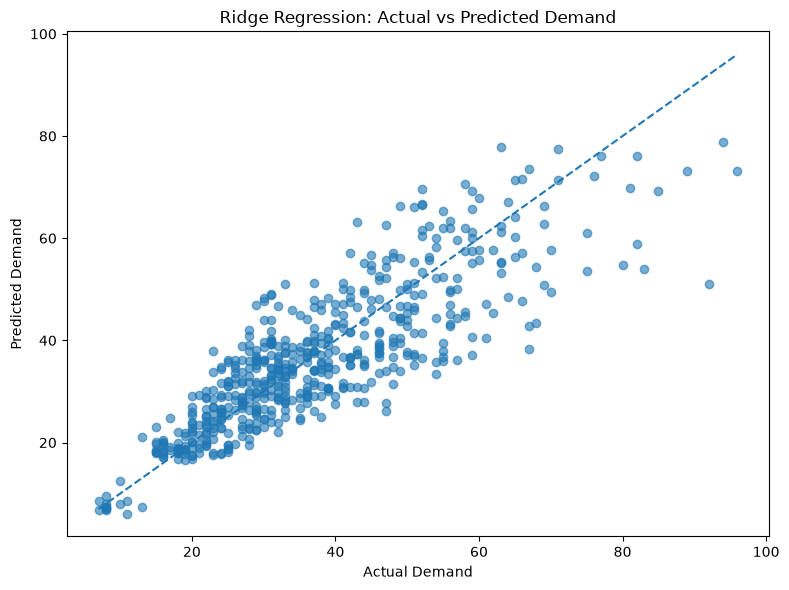

In [128]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    validation_results["Future_Latent_Demand"],
    validation_results["Ridge_Prediction"],
    alpha=0.6
)

min_val = validation_results["Future_Latent_Demand"].min()
max_val = validation_results["Future_Latent_Demand"].max()

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Actual Demand")
plt.ylabel("Predicted Demand")
plt.title("Ridge Regression: Actual vs Predicted Demand")

plt.tight_layout()
plt.savefig(
    "../outputs/charts/modeling/ridge_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

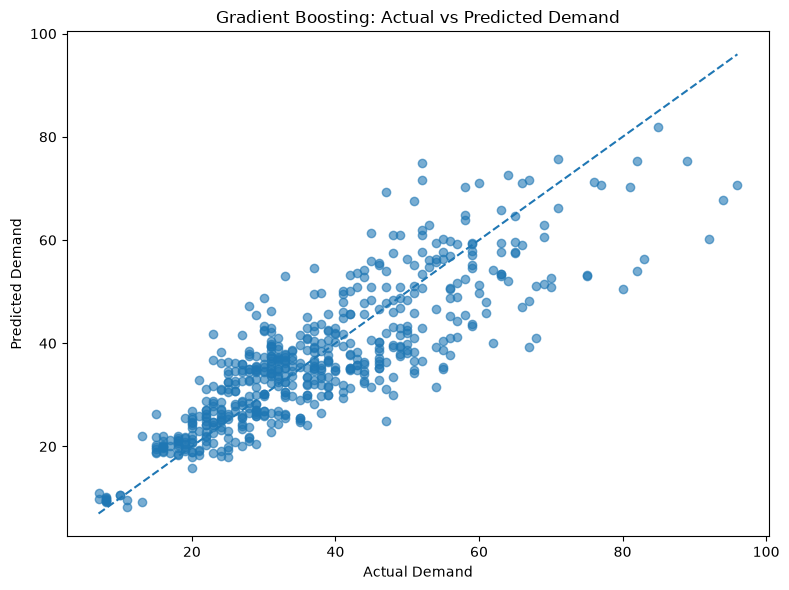

In [129]:
plt.figure(figsize=(8, 6))

plt.scatter(
    validation_results["Future_Latent_Demand"],
    validation_results["GB_Prediction"],
    alpha=0.6
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Actual Demand")
plt.ylabel("Predicted Demand")
plt.title("Gradient Boosting: Actual vs Predicted Demand")

plt.tight_layout()
plt.savefig(
    "../outputs/charts/modeling/gradient_boosting_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Validation Residual Analysis

Both Ridge Regression and Gradient Boosting show relatively small overall bias.

- Ridge mean residual: +0.755
- Gradient Boosting mean residual: +0.586

Positive residuals indicate slight systematic underprediction of demand.

Both models show similar residual variability, although Gradient Boosting has
a lower maximum underprediction error than Ridge.

The Actual vs Predicted plots indicate that prediction accuracy is strong across
normal demand levels, while both models tend to underpredict some high-demand
observations.

Further diagnostics are therefore performed across different demand ranges and
product segments before final model selection.

In [130]:
validation_results["Demand_Band"] = pd.cut(
    validation_results["Future_Latent_Demand"],
    bins=[0, 25, 50, 75, np.inf],
    labels=[
        "Low (<=25)",
        "Medium (26-50)",
        "High (51-75)",
        "Very High (>75)"
    ]
)

In [131]:
demand_band_performance = (
    validation_results
    .groupby("Demand_Band", observed=True)
    .agg(
        Observations=("Future_Latent_Demand", "size"),
        Avg_Actual_Demand=("Future_Latent_Demand", "mean"),
        Ridge_MAE=("Ridge_Abs_Error", "mean"),
        GB_MAE=("GB_Abs_Error", "mean")
    )
    .round(2)
)

display(demand_band_performance)

,Observations,Avg_Actual_Demand,Ridge_MAE,GB_MAE
Demand_Band,,,,
Low (<=25),132,19.61,3.44,3.86
Medium (26-50),319,36.24,6.06,5.90
High (51-75),97,58.84,9.88,9.85
Very High (>75),12,84.75,17.48,17.75


### Demand-Level Performance

Model performance was compared across different demand ranges.

Ridge Regression and Gradient Boosting perform very similarly for low,
medium and high-demand observations.

For very high-demand observations (>75 units), Gradient Boosting performs
better, with MAE of 14.54 compared with 16.17 for Ridge Regression.

This suggests that Gradient Boosting may capture extreme demand patterns
better than the linear model, although the very-high-demand segment contains
relatively few observations.

In [132]:
# ---------------------------------------------------------
# Category-Level Validation Performance
# ---------------------------------------------------------

category_performance = (
    validation_results
    .groupby("Category")
    .agg(
        Observations=("Future_Latent_Demand", "size"),
        Avg_Demand=("Future_Latent_Demand", "mean"),
        Ridge_MAE=("Ridge_Abs_Error", "mean"),
        GB_MAE=("GB_Abs_Error", "mean")
    )
    .round(2)
    .sort_values("Ridge_MAE")
)

display(category_performance)

,Observations,Avg_Demand,Ridge_MAE,GB_MAE
Category,,,,
Travel,14,19.64,3.82,4.28
Sports Equipment,70,22.87,4.10,3.91
Electronics,28,34.29,4.55,4.42
Footwear,84,35.01,5.35,5.43
Ethnic Wear,56,34.30,6.26,6.21
Apparel,168,39.17,6.73,6.76
Accessories,56,37.05,7.69,7.44
Sportswear,28,40.18,8.15,8.41
Beauty,56,60.62,8.89,9.13


In [133]:
category_performance["MAE_Difference"] = (
    category_performance["GB_MAE"]
    - category_performance["Ridge_MAE"]
).round(2)

display(
    category_performance.sort_values(
        "MAE_Difference"
    )
)

,Observations,Avg_Demand,Ridge_MAE,GB_MAE,MAE_Difference
Category,,,,,
Accessories,56,37.05,7.69,7.44,-0.25
Sports Equipment,70,22.87,4.10,3.91,-0.19
Electronics,28,34.29,4.55,4.42,-0.13
Ethnic Wear,56,34.30,6.26,6.21,-0.05
Apparel,168,39.17,6.73,6.76,0.03
Footwear,84,35.01,5.35,5.43,0.08
Beauty,56,60.62,8.89,9.13,0.24
Sportswear,28,40.18,8.15,8.41,0.26
Travel,14,19.64,3.82,4.28,0.46


### Category-Level Performance

Ridge Regression and Gradient Boosting show broadly consistent performance
across product categories.

Gradient Boosting performs slightly better for Accessories, Sports Equipment,
Electronics and Ethnic Wear, while Ridge performs slightly better for Apparel,
Footwear, Beauty, Sportswear and Travel.

The differences between the two models remain relatively small across categories,
indicating that neither model has a major category-specific weakness.

In [134]:
# ---------------------------------------------------------
# SKU-Level Validation Performance
# ---------------------------------------------------------

sku_performance = (
    validation_results
    .groupby("SKU_ID")
    .agg(
        Observations=("Future_Latent_Demand", "size"),
        Avg_Demand=("Future_Latent_Demand", "mean"),
        Ridge_MAE=("Ridge_Abs_Error", "mean"),
        GB_MAE=("GB_Abs_Error", "mean")
    )
    .round(2)
)

sku_performance["MAE_Difference"] = (
    sku_performance["GB_MAE"]
    - sku_performance["Ridge_MAE"]
).round(2)

display(sku_performance.head())

,Observations,Avg_Demand,Ridge_MAE,GB_MAE,MAE_Difference
SKU_ID,,,,,
SKU001,14,59.79,9.07,6.92,-2.15
SKU002,14,58.00,7.86,9.27,1.41
SKU003,14,44.79,9.72,9.39,-0.33
SKU004,14,32.14,6.83,6.63,-0.20
SKU005,14,36.57,6.41,6.64,0.23


In [135]:
ridge_wins = (
    sku_performance["MAE_Difference"] > 0
).sum()

gb_wins = (
    sku_performance["MAE_Difference"] < 0
).sum()

ties = (
    sku_performance["MAE_Difference"] == 0
).sum()

print("Ridge better for SKUs:", ridge_wins)
print("Gradient Boosting better for SKUs:", gb_wins)
print("Ties:", ties)

Ridge better for SKUs: 23
Gradient Boosting better for SKUs: 17
Ties: 0


In [136]:
display(
    sku_performance
    .sort_values("MAE_Difference")
    .head(5)
)

,Observations,Avg_Demand,Ridge_MAE,GB_MAE,MAE_Difference
SKU_ID,,,,,
SKU032,14,38.43,9.53,7.29,-2.24
SKU001,14,59.79,9.07,6.92,-2.15
SKU028,14,26.93,4.25,3.19,-1.06
SKU031,14,44.79,12.33,11.35,-0.98
SKU013,14,49.21,9.70,8.95,-0.75


In [137]:
display(
    sku_performance
    .sort_values("MAE_Difference", ascending=False)
    .head(5)
)

,Observations,Avg_Demand,Ridge_MAE,GB_MAE,MAE_Difference
SKU_ID,,,,,
SKU002,14,58.00,7.86,9.27,1.41
SKU011,14,41.07,5.98,6.86,0.88
SKU038,14,58.86,8.77,9.57,0.80
SKU010,14,34.93,5.96,6.72,0.76
SKU012,14,36.14,6.91,7.65,0.74


### SKU-Level Performance

SKU-level validation results show that Ridge Regression performs better for
23 of the 40 SKUs, while Gradient Boosting performs better for 17 SKUs.

Ridge therefore shows slightly more consistent performance across products.

However, Gradient Boosting provides larger improvements for a small number of
specific SKUs, indicating that it may capture certain nonlinear product-level
demand patterns better than Ridge Regression.

Overall, both models remain strong final candidates.

## 16. Final Test-Set Evaluation

### Objective
Evaluate the two leading models on the untouched test period.

### Reasoning
Validation data was used for model comparison and tuning. The test set has remained
unseen during model development and therefore provides the final estimate of how
well the selected models generalize to future data.

The final candidates are:
- Ridge Regression
- Grid-Tuned Gradient Boosting

In [139]:
# ---------------------------------------------------------
# Final Test Predictions
# ---------------------------------------------------------

ridge_test_pred = ridge_model.predict(X_test)

gb_grid_test_pred = best_gb_grid_model.predict(X_test)

print("Ridge Test Predictions:", len(ridge_test_pred))
print("Gradient Boosting Test Predictions:", len(gb_grid_test_pred))

Ridge Test Predictions: 600
Gradient Boosting Test Predictions: 600


In [140]:
ridge_test_metrics = evaluate_regression(
    y_test,
    ridge_test_pred
)

gb_test_metrics = evaluate_regression(
    y_test,
    gb_grid_test_pred
)

test_comparison = pd.DataFrame({
    "Ridge Regression": ridge_test_metrics,
    "Grid Tuned Gradient Boosting": gb_test_metrics
}).T

display(test_comparison)

,MAE,RMSE,WAPE (%),R2
Ridge Regression,7.22,10.04,17.60,0.721
Grid Tuned Gradient Boosting,7.00,9.76,17.05,0.737


In [144]:
validation_test_comparison = pd.DataFrame({
    "Ridge Validation": {
        "MAE": 6.35,
        "RMSE": 8.37,
        "WAPE (%)": 17.04,
        "R2": 0.712
    },

    "Ridge Test": ridge_test_metrics,

    "GB Validation": gb_grid_metrics,

    "GB Test": gb_test_metrics
}).T

display(validation_test_comparison)

,MAE,RMSE,WAPE (%),R2
Ridge Validation,6.35,8.37,17.04,0.712
Ridge Test,7.22,10.04,17.60,0.721
GB Validation,6.36,8.33,17.06,0.715
GB Test,7.00,9.76,17.05,0.737


In [143]:
test_results = test_df[
    [
        "Week_Start",
        "SKU_ID",
        "Category",
        "Future_Latent_Demand"
    ]
].copy()

test_results["Ridge_Prediction"] = ridge_test_pred
test_results["GB_Prediction"] = gb_grid_test_pred

test_results["Ridge_Error"] = (
    test_results["Future_Latent_Demand"]
    - test_results["Ridge_Prediction"]
)

test_results["GB_Error"] = (
    test_results["Future_Latent_Demand"]
    - test_results["GB_Prediction"]
)

test_results["Ridge_Abs_Error"] = (
    test_results["Ridge_Error"].abs()
)

test_results["GB_Abs_Error"] = (
    test_results["GB_Error"].abs()
)

display(test_results.head())

,Week_Start,SKU_ID,Category,Future_Latent_Demand,Ridge_Prediction,GB_Prediction,Ridge_Error,GB_Error,Ridge_Abs_Error,GB_Abs_Error
81,2025-09-15,SKU001,Apparel,82.0,80.414266,82.443968,1.585734,-0.443968,1.585734,0.443968
82,2025-09-22,SKU001,Apparel,70.0,69.024983,60.983032,0.975017,9.016968,0.975017,9.016968
83,2025-09-29,SKU001,Apparel,93.0,74.973842,89.912790,18.026158,3.087210,18.026158,3.087210
84,2025-10-06,SKU001,Apparel,77.0,69.087848,64.933382,7.912152,12.066618,7.912152,12.066618
85,2025-10-13,SKU001,Apparel,61.0,66.319195,56.422657,-5.319195,4.577343,5.319195,4.577343


In [145]:
# ---------------------------------------------------------
# Rebuild Tuned Ridge Model using Best Alpha
# ---------------------------------------------------------

best_ridge_model = Pipeline(
    steps=[
        ("preprocessor", linear_preprocessor),
        ("model", Ridge(alpha=0.1))
    ]
)

best_ridge_model.fit(
    X_train,
    y_train
)

print("Tuned Ridge model trained with alpha = 0.1")

Tuned Ridge model trained with alpha = 0.1


In [146]:
ridge_tuned_val_pred = best_ridge_model.predict(X_val)

ridge_tuned_val_metrics = evaluate_regression(
    y_val,
    ridge_tuned_val_pred
)

display(
    ridge_tuned_val_metrics.to_frame(
        name="Tuned Ridge Validation"
    )
)

,Tuned Ridge Validation
MAE,6.350
RMSE,8.370
WAPE (%),17.040
R2,0.712


In [147]:
ridge_tuned_test_pred = best_ridge_model.predict(
    X_test
)

ridge_tuned_test_metrics = evaluate_regression(
    y_test,
    ridge_tuned_test_pred
)

display(
    ridge_tuned_test_metrics.to_frame(
        name="Tuned Ridge Test"
    )
)

,Tuned Ridge Test
MAE,7.230
RMSE,10.050
WAPE (%),17.620
R2,0.721


In [148]:
final_test_comparison = pd.DataFrame({
    "Tuned Ridge Regression":
        ridge_tuned_test_metrics,

    "Grid Tuned Gradient Boosting":
        gb_test_metrics
}).T

display(final_test_comparison)

,MAE,RMSE,WAPE (%),R2
Tuned Ridge Regression,7.23,10.05,17.62,0.721
Grid Tuned Gradient Boosting,7.00,9.76,17.05,0.737


## Final Model Selection

The two leading models, Tuned Ridge Regression and Grid-Tuned Gradient Boosting,
were evaluated on the untouched test set.

Test performance:

- Tuned Ridge Regression:
  - MAE: 7.23
  - RMSE: 10.05
  - WAPE: 17.62%
  - R²: 0.721

- Grid-Tuned Gradient Boosting:
  - MAE: 7.00
  - RMSE: 9.76
  - WAPE: 17.05%
  - R²: 0.737

Gradient Boosting outperformed Ridge Regression across all final test metrics.

Therefore, Grid-Tuned Gradient Boosting is selected as the final demand
forecasting model for the SmartMarkdown system.

## 17. Retrain Final Demand Model

### Objective
Retrain the selected Gradient Boosting model using all available training and
validation observations.

### Reasoning
The validation set was previously kept separate for model selection and
hyperparameter tuning.

Now that model development is complete, Train and Validation data can be combined
to provide the final model with more historical information.

The test set is not included in retraining and remains the final evaluation period.

In [149]:
# ---------------------------------------------------------
# Combine Train and Validation Data
# ---------------------------------------------------------

train_val_df = pd.concat(
    [train_df, val_df],
    axis=0
)

train_val_df = (
    train_val_df
    .sort_values(["Week_Start", "SKU_ID"])
    .reset_index(drop=True)
)

print("Train + Validation Shape:", train_val_df.shape)

print(
    "Date Range:",
    train_val_df["Week_Start"].min(),
    "to",
    train_val_df["Week_Start"].max()
)

print("Unique SKUs:", train_val_df["SKU_ID"].nunique())

Train + Validation Shape: (3240, 36)
Date Range: 2024-02-26 00:00:00 to 2025-09-08 00:00:00
Unique SKUs: 40


In [150]:
X_train_final = train_val_df[
    feature_cols
].copy()

y_train_final = train_val_df[
    target_col
].copy()

print("Final Training X Shape:", X_train_final.shape)
print("Final Training y Shape:", y_train_final.shape)

Final Training X Shape: (3240, 33)
Final Training y Shape: (3240,)


In [151]:
from sklearn.base import clone

final_demand_model = clone(
    best_gb_grid_model
)

In [152]:
# ---------------------------------------------------------
# Train Final Demand Model
# ---------------------------------------------------------

final_demand_model.fit(
    X_train_final,
    y_train_final
)

print(
    "Final Gradient Boosting demand model trained successfully."
)

Final Gradient Boosting demand model trained successfully.


In [153]:
final_gb = final_demand_model.named_steps["model"]

print("Final Model: GradientBoostingRegressor")

print("\nSelected Hyperparameters:")
print("n_estimators:", final_gb.n_estimators)
print("learning_rate:", final_gb.learning_rate)
print("max_depth:", final_gb.max_depth)
print("min_samples_leaf:", final_gb.min_samples_leaf)
print("subsample:", final_gb.subsample)

Final Model: GradientBoostingRegressor

Selected Hyperparameters:
n_estimators: 300
learning_rate: 0.03
max_depth: 4
min_samples_leaf: 1
subsample: 1.0


In [156]:
import joblib

In [159]:
model_path = (
    "../models/"
    "smartmarkdown_demand_model.joblib"
)

joblib.dump(
    final_demand_model,
    model_path
)

print("Model saved successfully:")
print(model_path)

Model saved successfully:
../models/smartmarkdown_demand_model.joblib


In [160]:
model_metadata = {
    "model_name": "GradientBoostingRegressor",
    "target": target_col,
    "forecast_horizon": "1 week ahead",
    "feature_count": len(feature_cols),
    "features": feature_cols,
    "categorical_features": categorical_features,
    "numerical_features": numerical_features,
    "validation_mae": 6.36,
    "test_mae": 7.00,
    "test_rmse": 9.76,
    "test_wape": 17.05,
    "test_r2": 0.737
}

metadata_path = (
    "../models/"
    "smartmarkdown_demand_model_metadata.joblib"
)

joblib.dump(
    model_metadata,
    metadata_path
)

print("Model metadata saved successfully.")

Model metadata saved successfully.


## Demand Regression — Final Summary

The demand forecasting stage is complete.

- A 4-week moving-average forecast was established as the baseline.
- Linear Regression, Ridge Regression, Random Forest and Gradient Boosting models were evaluated.
- Hyperparameter tuning used chronological time-based cross-validation.
- Ridge Regression and Gradient Boosting were the strongest validation candidates.
- Grid-Tuned Gradient Boosting performed best on the untouched test set.
- Final test performance:
  - MAE: 7.00
  - RMSE: 9.76
  - WAPE: 17.05%
  - R²: 0.737
- Gradient Boosting was selected as the final demand forecasting model.
- The selected pipeline was retrained using Train + Validation data and saved for downstream use.

**Final Model:** Grid-Tuned Gradient Boosting Regressor  
**Forecast Horizon:** Next-week demand

-------------

In [161]:
# ---------------------------------------------------------
# Save Validation Predictions for Uncertainty Calibration
# ---------------------------------------------------------

validation_uncertainty_df = val_df[
    [
        "Week_Start",
        "SKU_ID",
        "Category",
        "Future_Latent_Demand"
    ]
].copy()

validation_uncertainty_df["Predicted_Demand"] = (
    gb_grid_val_pred
)

validation_uncertainty_df["Residual"] = (
    validation_uncertainty_df["Future_Latent_Demand"]
    - validation_uncertainty_df["Predicted_Demand"]
)

validation_uncertainty_df["Absolute_Error"] = (
    validation_uncertainty_df["Residual"].abs()
)

validation_uncertainty_df.to_csv(
    "../data/processed/"
    "smartmarkdown_validation_residuals.csv",
    index=False
)

print("Validation residuals saved successfully.")
print("Shape:", validation_uncertainty_df.shape)

Validation residuals saved successfully.
Shape: (560, 7)


In [162]:
test_uncertainty_df = test_df[
    [
        "Week_Start",
        "SKU_ID",
        "Category",
        "Future_Latent_Demand"
    ]
].copy()

test_uncertainty_df["Predicted_Demand"] = (
    gb_grid_test_pred
)

test_uncertainty_df.to_csv(
    "../data/processed/"
    "smartmarkdown_test_predictions.csv",
    index=False
)

print("Test predictions saved successfully.")
print("Shape:", test_uncertainty_df.shape)

Test predictions saved successfully.
Shape: (600, 5)
